1. Addressing Nulls in the data set for the Full-time employment column

In [ ]:
'''
The purpose of this notebook is to compare imputation techniques for handling nulls in our
dataset

'''

In [1]:
import polars as pl
import pandas as pd 

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import plotly.express as px
import plotly.graph_objects as go

In [4]:
dp_Processed_TS_Data = pl.scan_parquet('prepared_data/Tbl_Provincial_NOC_Labor_Statistics.parquet')

In [5]:
dp_Processed_TS_Data.schema

C:\Users\tejas\AppData\Local\Temp\ipykernel_19052\2045662772.py:1: PerformanceWarning: Resolving the schema of a LazyFrame is a potentially expensive operation. Use `LazyFrame.collect_schema()` to get the schema without this warning.
  dp_Processed_TS_Data.schema


Schema([('ProvinceID', Float64),
        ('DGUID', String),
        ('NOC_GroupingID', Float64),
        ('datestamp', Datetime(time_unit='ns', time_zone=None)),
        ('Employment', Float64),
        ('Full-time employment', Float64),
        ('Labour force', Float64),
        ('Part-time employment', Float64),
        ('Unemployment', Float64),
        ('Unemployment rate', Float64),
        ('NOC_Grouping', String),
        ('Province', String),
        ('Employment Moving Average', Float64),
        ('Employment Moving SD', Float64),
        ('Employment Upper Band', Float64),
        ('Employment Lower Band', Float64),
        ('EntryID', Int64)])

In [6]:
#The schema is congruent with expectations 

df_Focused_Target = dp_Processed_TS_Data.select(['ProvinceID','Province','NOC_GroupingID','NOC_Grouping','datestamp','Full-time employment']).collect().to_pandas().sort_values(by=['ProvinceID','NOC_GroupingID','datestamp'],ascending=True)
df_Focused_Target

,ProvinceID,Province,NOC_GroupingID,NOC_Grouping,datestamp,Full-time employment
0,10.0,Newfoundland and Labrador,1.0,"Total, all occupations",2000-01-01,151.6
1,10.0,Newfoundland and Labrador,1.0,"Total, all occupations",2000-02-01,152.1
2,10.0,Newfoundland and Labrador,1.0,"Total, all occupations",2000-03-01,152.5
3,10.0,Newfoundland and Labrador,1.0,"Total, all occupations",2000-04-01,156.7
4,10.0,Newfoundland and Labrador,1.0,"Total, all occupations",2000-05-01,170.9
...,...,...,...,...,...,...
181558,59.0,British Columbia,59.0,"Labourers in processing, manufacturing and uti...",2025-05-01,18.3
181559,59.0,British Columbia,59.0,"Labourers in processing, manufacturing and uti...",2025-06-01,17.0
181560,59.0,British Columbia,59.0,"Labourers in processing, manufacturing and uti...",2025-07-01,15.6
181561,59.0,British Columbia,59.0,"Labourers in processing, manufacturing and uti...",2025-08-01,12.6


In [7]:
df_Series_Count = df_Focused_Target[['ProvinceID','NOC_GroupingID']].drop_duplicates()
df_Series_Count

,ProvinceID,NOC_GroupingID
0,10.0,1.0
309,10.0,2.0
618,10.0,3.0
859,10.0,4.0
1168,10.0,5.0
...,...,...
180018,59.0,55.0
180327,59.0,56.0
180636,59.0,57.0
180945,59.0,58.0


In [8]:
#We need to determine the best imputation method, but first we should determine 
#per ProvinceID and NOC_GroupingID pair, how many sequential nulls there are and address any issues 

#Boolean Null Mask
Null_Mask = df_Focused_Target['Full-time employment'].isna()

#Used OpenAI to generate this, it helps identify consecutive nulls 
Run_IDs = Null_Mask.ne(Null_Mask.shift()).cumsum()

Run_IDs.head()

0    1
1    1
2    1
3    1
4    1
Name: Full-time employment, dtype: int32

In [9]:
Null_Mask.head()

0    False
1    False
2    False
3    False
4    False
Name: Full-time employment, dtype: bool

In [10]:
#Counts the number of Null Run Sequences per Combination 
Null_Runs = (
    df_Focused_Target[Null_Mask]
    .groupby(['ProvinceID','NOC_GroupingID', Run_IDs])
    .size()
)

Null_Runs

ProvinceID  NOC_GroupingID  Full-time employment
10.0        3.0             2                       1
                            4                       1
                            6                       1
                            8                       1
                            10                      2
                                                   ..
48.0        42.0            1266                    1
                            1268                    1
                            1270                    1
                            1272                    1
59.0        42.0            1274                    1
Length: 637, dtype: int64

In [11]:
# Get max sequntial null run per group
max_null_sequence = (
    Null_Runs
    .groupby(['ProvinceID','NOC_GroupingID'])
    .max()
    .reset_index(name='Max_Null_Sequence')
)

max_null_sequence['Max_Null_Sequence'].describe()

count    59.000000
mean      3.389831
std       3.189514
min       1.000000
25%       1.000000
50%       2.000000
75%       4.000000
max      17.000000
Name: Max_Null_Sequence, dtype: float64

In [12]:
max_null_sequence[max_null_sequence['Max_Null_Sequence'] >= 5]

,ProvinceID,NOC_GroupingID,Max_Null_Sequence
3,10.0,23.0,5
7,10.0,36.0,8
8,10.0,39.0,5
9,10.0,40.0,7
10,10.0,41.0,7
11,10.0,42.0,10
18,11.0,23.0,8
24,11.0,37.0,17
27,11.0,41.0,10
28,11.0,42.0,10


In [13]:
#We need to drop these combination because they gaps are far to large 

Sample = df_Focused_Target[(df_Focused_Target['ProvinceID'] == 11) & (df_Focused_Target['NOC_GroupingID'] == 37)]
Sample

,ProvinceID,Province,NOC_GroupingID,NOC_Grouping,datestamp,Full-time employment
28773,11.0,Prince Edward Island,37.0,Care providers and public protection support o...,2000-01-01,0.4
28774,11.0,Prince Edward Island,37.0,Care providers and public protection support o...,2000-02-01,0.3
28775,11.0,Prince Edward Island,37.0,Care providers and public protection support o...,2000-03-01,0.4
28776,11.0,Prince Edward Island,37.0,Care providers and public protection support o...,2000-04-01,0.2
28777,11.0,Prince Edward Island,37.0,Care providers and public protection support o...,2000-05-01,0.3
...,...,...,...,...,...,...
29063,11.0,Prince Edward Island,37.0,Care providers and public protection support o...,2025-03-01,NaN
29064,11.0,Prince Edward Island,37.0,Care providers and public protection support o...,2025-04-01,NaN
29065,11.0,Prince Edward Island,37.0,Care providers and public protection support o...,2025-06-01,0.2
29066,11.0,Prince Edward Island,37.0,Care providers and public protection support o...,2025-07-01,0.3


In [14]:
Sample['Is_Null'] = Sample['Full-time employment'].isna()


C:\Users\tejas\AppData\Local\Temp\ipykernel_19052\3513300991.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Sample['Is_Null'] = Sample['Full-time employment'].isna()


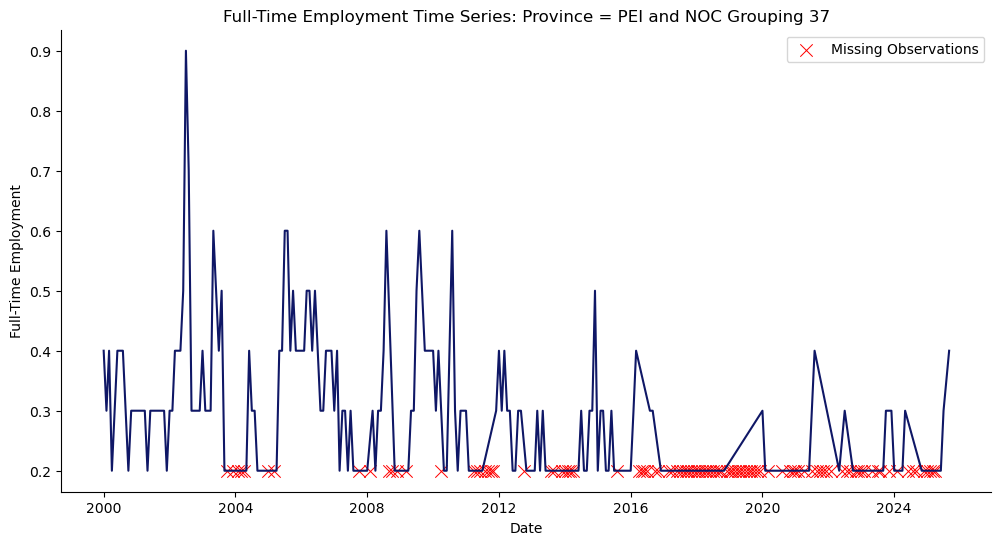

In [15]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=Sample,
    x='datestamp',
    y='Full-time employment',
    color='#0F1766'
)

sns.scatterplot(
    data=Sample[Sample['Is_Null']],
    x='datestamp',
    y=[Sample['Full-time employment'].min()] * Sample['Is_Null'].sum(),
    color='red',
    marker='x',
    s=80,
    label='Missing Observations'
)

sns.despine()

plt.title("Full-Time Employment Time Series: Province = PEI and NOC Grouping 37")
plt.xlabel("Date")
plt.ylabel("Full-Time Employment")

plt.show()



In [16]:
#Saving Plot for documentation 
Null_Fig_Example = px.line(
    data_frame=Sample,
    x='datestamp',
    y='Full-time employment',
    title='Full-Time Employment Time Series: Province = PEI and NOC Grouping 37',
    height=900,
    width=1500,
)

Null_Fig_Example.update_traces(
    line=dict(width=2.5, color='#0F1E69')
)


Null_Fig_Example.update_layout(
    plot_bgcolor="#C9CAD1",
    title_font=dict(size=16),  
            font=dict(size=15),  
            hoverlabel=dict(
                font_size=20  
            ),
            xaxis=dict(
                title='Datestamp (Monthly)',
                title_font=dict(size=18), 
                tickfont=dict(size=12)  
            ),
            yaxis=dict(
                title='Full-Time Employment (In Persons Thousands)',
                title_font=dict(size=18), 
                tickfont=dict(size=12)  
            ),
)



Null_Fig_Example.show()

In [17]:
Null_Fig_Example.write_image('Null_Sequence.svg')